# CardioIA Fase 4 | Parte 2a: CNN treinada do zero

Classifica raios-X em **cardiomegalia** (1) ou **sem achado** (0).

Precisa das imagens geradas pela Parte 1 em `dados/processados/`.

> Trabalho acadêmico. Não serve para diagnóstico.

In [1]:
import json
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

SEMENTE = 42
TAMANHO_DA_IMAGEM = (224, 224)
IMAGENS_POR_LOTE = 32
MAXIMO_DE_EPOCAS = 60
LIMIAR_DE_DECISAO = 0.5
CLASSES = ["sem_achado", "cardiomegalia"]

esta_no_colab = Path("/content").exists()
PASTA_DADOS = Path("/content/dados") if esta_no_colab else Path("../dados")
PASTA_MODELOS = Path("/content/modelos") if esta_no_colab else Path("../modelos")
PASTA_PROCESSADOS = PASTA_DADOS / "processados"
PASTA_PRINTS = Path("prints")
assert PASTA_PROCESSADOS.exists(), "Rode a Parte 1 ou descompacte dados_processados.zip (release parte-a)"
PASTA_MODELOS.mkdir(exist_ok=True)
PASTA_PRINTS.mkdir(exist_ok=True)

keras.utils.set_random_seed(SEMENTE)

## 1. Carregar as imagens

In [2]:
def carregar(conjunto, embaralhar):
    return keras.utils.image_dataset_from_directory(
        PASTA_PROCESSADOS / conjunto,
        class_names=CLASSES,
        label_mode="binary",
        color_mode="grayscale",
        image_size=TAMANHO_DA_IMAGEM,
        batch_size=IMAGENS_POR_LOTE,
        shuffle=embaralhar,
        seed=SEMENTE,
    )


treino = carregar("treino", embaralhar=True)
validacao = carregar("validacao", embaralhar=False)
teste = carregar("teste", embaralhar=False)
arquivos_de_teste = [Path(caminho).name for caminho in teste.file_paths]

Found 1563 files belonging to 2 classes.


Found 335 files belonging to 2 classes.


Found 336 files belonging to 2 classes.


## 2. Montar a rede

Quatro blocos de convolução: cada um dobra os filtros e corta a imagem pela metade.

O aumento de dados é leve e **sem espelhamento horizontal**: espelhar colocaria o coração do lado
errado do peito.

In [3]:
aumento_de_dados = keras.Sequential(
    [
        layers.RandomRotation(factor=0.02),
        layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
        layers.RandomZoom(height_factor=0.05),
    ],
    name="aumento_de_dados",
)


def bloco_de_convolucao(entrada, quantidade_de_filtros):
    saida = layers.Conv2D(quantidade_de_filtros, kernel_size=3, padding="same", use_bias=False)(entrada)
    saida = layers.BatchNormalization()(saida)
    saida = layers.ReLU()(saida)
    return layers.MaxPooling2D()(saida)


entrada = keras.Input(shape=(*TAMANHO_DA_IMAGEM, 1))
saida = aumento_de_dados(entrada)
saida = layers.Rescaling(1 / 255)(saida)
for quantidade_de_filtros in [16, 32, 64, 128]:
    saida = bloco_de_convolucao(saida, quantidade_de_filtros)
saida = layers.GlobalAveragePooling2D()(saida)
saida = layers.Dropout(0.3)(saida)
saida = layers.Dense(1, activation="sigmoid", name="probabilidade_de_cardiomegalia")(saida)

cnn = keras.Model(entrada, saida, name="cnn_do_zero")
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_de_dados (Sequential)   │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidade_de_cardiomegalia  │ (None, 1)              │           129 │
│ (Dense)                         │                        │             

 Total params: 98,001 (382.82 KB)

 Trainable params: 97,521 (380.94 KB)

 Non-trainable params: 480 (1.88 KB)

## 3. Treinar

O treino para quando a validação deixa de melhorar e volta para a melhor época.
O conjunto de teste não participa de nenhuma escolha.

In [4]:
parar_quando_estagnar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)
reduzir_passo = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)

historico = cnn.fit(
    treino,
    validation_data=validacao,
    epochs=MAXIMO_DE_EPOCAS,
    callbacks=[parar_quando_estagnar, reduzir_passo],
    verbose=2,
)
cnn.save(PASTA_MODELOS / "cnn_do_zero.keras")

Epoch 1/60


49/49 - 11s - 227ms/step - accuracy: 0.5822 - loss: 0.6947 - val_accuracy: 0.4955 - val_loss: 0.7136 - learning_rate: 0.0010


Epoch 2/60


49/49 - 10s - 212ms/step - accuracy: 0.6296 - loss: 0.6440 - val_accuracy: 0.4925 - val_loss: 0.7582 - learning_rate: 0.0010


Epoch 3/60


49/49 - 10s - 213ms/step - accuracy: 0.6296 - loss: 0.6527 - val_accuracy: 0.5104 - val_loss: 0.7883 - learning_rate: 0.0010


... (62 outputs left out)

Epoch 35/60


49/49 - 10s - 213ms/step - accuracy: 0.7223 - loss: 0.5451 - val_accuracy: 0.6866 - val_loss: 0.6008 - learning_rate: 1.2500e-04


Epoch 36/60


49/49 - 10s - 213ms/step - accuracy: 0.7281 - loss: 0.5377 - val_accuracy: 0.7224 - val_loss: 0.5624 - learning_rate: 1.2500e-04


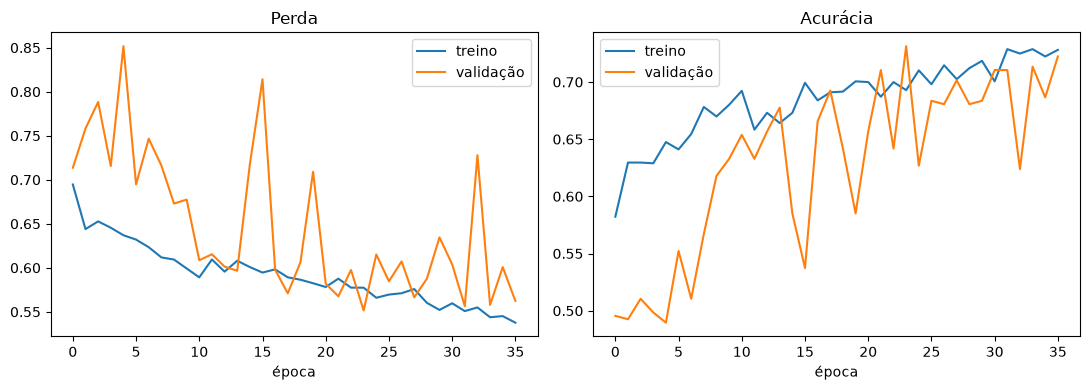

In [5]:
figura, (eixo_perda, eixo_acuracia) = plt.subplots(1, 2, figsize=(11, 4))
eixo_perda.plot(historico.history["loss"], label="treino")
eixo_perda.plot(historico.history["val_loss"], label="validação")
eixo_perda.set(title="Perda", xlabel="época")
eixo_perda.legend()
eixo_acuracia.plot(historico.history["accuracy"], label="treino")
eixo_acuracia.plot(historico.history["val_accuracy"], label="validação")
eixo_acuracia.set(title="Acurácia", xlabel="época")
eixo_acuracia.legend()
figura.tight_layout()
figura.savefig(PASTA_PRINTS / "curvas_de_treino.png", dpi=120)
plt.show()

## 4. Avaliar no teste

In [6]:
def respostas_verdadeiras(dados):
    return np.concatenate([rotulos.numpy() for _, rotulos in dados]).ravel().astype(int)


verdadeiras = respostas_verdadeiras(teste)
probabilidades = cnn.predict(teste, verbose=0).ravel()
previstas = (probabilidades >= LIMIAR_DE_DECISAO).astype(int)

metricas = {
    "imagens_de_teste": len(verdadeiras),
    "acuracia": accuracy_score(verdadeiras, previstas),
    "precisao": precision_score(verdadeiras, previstas),
    "recall": recall_score(verdadeiras, previstas),
    "f1": f1_score(verdadeiras, previstas),
    "auc": roc_auc_score(verdadeiras, probabilidades),
}
metricas = {nome: round(float(valor), 3) for nome, valor in metricas.items()}
Path("metricas.json").write_text(json.dumps(metricas, indent=2) + "\n")
print(pd.Series(metricas).to_string())

imagens_de_teste    336.000
acuracia              0.679
precisao              0.708
recall                0.607
f1                    0.654
auc                   0.779


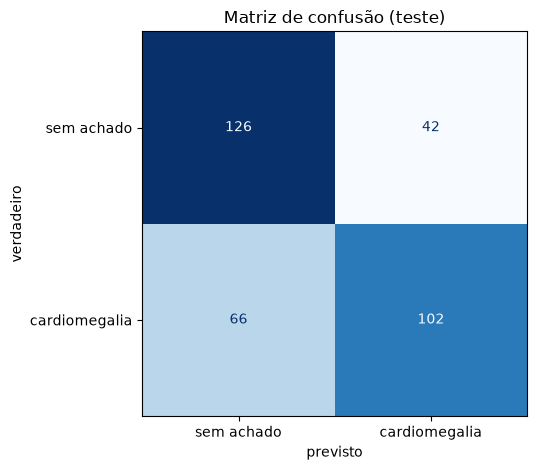

In [7]:
matriz = confusion_matrix(verdadeiras, previstas)
grafico = ConfusionMatrixDisplay(matriz, display_labels=["sem achado", "cardiomegalia"])
grafico.plot(cmap="Blues", colorbar=False)
grafico.ax_.set(title="Matriz de confusão (teste)", xlabel="previsto", ylabel="verdadeiro")
grafico.figure_.tight_layout()
grafico.figure_.savefig(PASTA_PRINTS / "matriz_de_confusao.png", dpi=120)
plt.show()

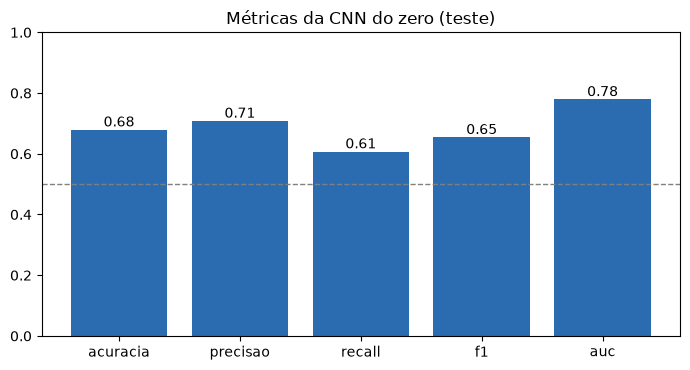

In [8]:
metricas_para_o_grafico = {nome: metricas[nome] for nome in ["acuracia", "precisao", "recall", "f1", "auc"]}
figura, eixo = plt.subplots(figsize=(7, 3.8))
barras = eixo.bar(list(metricas_para_o_grafico.keys()), list(metricas_para_o_grafico.values()), color="#2b6cb0")
eixo.bar_label(barras, fmt="%.2f")
eixo.axhline(0.5, color="gray", linestyle="--", linewidth=1)
eixo.set(title="Métricas da CNN do zero (teste)", ylim=(0, 1))
figura.tight_layout()
figura.savefig(PASTA_PRINTS / "metricas.png", dpi=120)
plt.show()

## 5. Guardar as previsões para a análise de fairness

In [9]:
previsoes = pd.DataFrame(
    {
        "arquivo": arquivos_de_teste,
        "verdadeira": verdadeiras,
        "prevista": previstas,
        "probabilidade": probabilidades,
    }
)
previsoes.to_csv(PASTA_DADOS / "previsoes_teste.csv", index=False)